# A Catholic Introduction to Artificial Intelligence
## Final Project — Module 3: Building and Evaluating the Model
### Classes 5 & 6

---

> *"Important and sensitive decisions — concerning employment, credit, access to public services or even a person's reputation — risk being fully delegated to automated systems that do not know compassion, mercy, forgiveness, and above all, the hope that people are able to change."*
> — Pope Leo XIV, *Magnifica Humanitas*, no. 102

---

## Module Overview

In Module 2 you analyzed the data deeply and made deliberate decisions about which features to include in your model. Now we build it.

This module introduces the full machine learning workflow:
1. **Prepare** the data for modeling
2. **Split** it into training and test sets
3. **Train** two different model types and understand what they are actually doing
4. **Evaluate** the models honestly — and discover that accuracy alone is a dangerously incomplete metric
5. **Interpret** the model's predictions and understand where it fails

By the end of this module, you will have a working predictive model — and a clear-eyed understanding of why a model that is "86% accurate" can still cause significant harm.

---

In [1]:
%pip install seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay
)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)

# Load and prepare data (same as Module 2)
df = pd.read_csv('synthetic_homework_dataset.csv',
                 parse_dates=['date_assigned', 'date_submitted'])

# Engineered features from Module 2
# (Only features known BEFORE the student starts are rebuilt here.
#  Process and leaky features from Module 2 are not used by the model.)
df['time_pressure'] = df['difficulty'] / df['days_until_due']

# The student's HABIT of deadline usage, averaged over EARLIER assignments only.
# deadline_usage is an intermediate step here; it is never used as a feature.
df = df.sort_values(['student_id', 'date_assigned'])
deadline_usage = ((df['date_submitted'] - df['date_assigned']).dt.days
                  / df['days_until_due'])
df['prior_deadline_usage'] = (
    deadline_usage.groupby(df['student_id'])
                  .transform(lambda s: s.shift().expanding().mean())
)

# Each student's first assignment has no history, so fill it with the median
df['prior_deadline_usage'] = df['prior_deadline_usage'].fillna(df['prior_deadline_usage'].median())

# Restore the original row order so the train/test split below is unchanged
df = df.sort_index()

# Encode the categorical assignment_type column as a number. LabelEncoder will encode the assignment types as integers, which is suitable for tree-based models like Decision Trees. For models that require one-hot encoding (like Logistic Regression), you would typically use pd.get_dummies or OneHotEncoder instead.

le = LabelEncoder()
df['assignment_type_enc'] = le.fit_transform(df['assignment_type']) # type: ignore
print('Assignment type encoding:', dict(zip(le.classes_, le.transform(le.classes_)))) # type: ignore

print(f'\nData loaded: {len(df)} rows')

Assignment type encoding: {'coding': np.int64(0), 'essay': np.int64(1), 'quiz_prep': np.int64(2), 'reading': np.int64(3), 'worksheet': np.int64(4)}

Data loaded: 500 rows


---

## Part 1: Preparing the Data for Modeling

Before training any model, we need to make three decisions:
1. **Which features to use** — your decision from Module 2
2. **How to split the data** into training and test sets
3. **Whether to scale the features** — required for logistic regression

### Why Do We Need a Train/Test Split?

If we trained and evaluated the model on the same data, we would be measuring how well it memorized the data — not how well it generalizes to new students and assignments it has never seen. This is like letting a student study the exact exam questions in advance: the score tells you nothing about whether they actually learned the material.

We hold out 20% of the data as a **test set** — the model never sees this data during training. After training, we evaluate performance on the test set only. This gives us an honest estimate of how the model would perform on new data.

In [4]:
# FEATURE SELECTION
# We define two feature sets so we can compare them:
#
# CONSERVATIVE: Uses only assignment properties + one engineered feature
#               No student history — avoids the feedback loop problem
#
# FULL: Also includes prior_completion_rate and prior_deadline_usage
#       (student history) — stronger predictors, higher ethical stakes
#
# You can also plug in your own feature set from Module 2 decisions.

CONSERVATIVE_FEATURES = [
    'num_questions',
    'difficulty',
    'days_until_due',
    'prior_avg_homework_time',
    'time_pressure',
]

FULL_FEATURES = CONSERVATIVE_FEATURES + [
    'prior_completion_rate',
    'prior_deadline_usage',
]

# ── CHOOSE WHICH FEATURE SET TO USE ──
# Change this to CONSERVATIVE_FEATURES to compare
SELECTED_FEATURES = FULL_FEATURES

# Target variable
TARGET = 'completed_on_time'

# Build X and y
X = df[SELECTED_FEATURES]
y = df[TARGET]

print(f'Features selected: {SELECTED_FEATURES}')
print(f'X shape: {X.shape}')
print(f'Class balance: {y.value_counts().to_dict()} ({y.mean()*100:.1f}% on time)')

Features selected: ['num_questions', 'difficulty', 'days_until_due', 'prior_avg_homework_time', 'time_pressure', 'prior_completion_rate', 'prior_deadline_usage']
X shape: (500, 7)
Class balance: {1: 429, 0: 71} (85.8% on time)


In [5]:
# ── TRAIN / TEST SPLIT ──
# random_state=42 ensures everyone gets the same split
# stratify=y ensures the on-time/late ratio is preserved in both sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f'Training set:  {len(X_train)} rows ({y_train.mean()*100:.1f}% on time)')
print(f'Test set:      {len(X_test)} rows ({y_test.mean()*100:.1f}% on time)')
print()
print(f'The model will be trained on {len(X_train)} examples.')
print(f'It will be evaluated on {len(X_test)} examples it has NEVER seen.')

Training set:  400 rows (85.8% on time)
Test set:      100 rows (86.0% on time)

The model will be trained on 400 examples.
It will be evaluated on 100 examples it has NEVER seen.


In [6]:
# ── FEATURE SCALING ──
#
# StandardScaler transforms each feature to have mean=0 and std=1.
# IMPORTANT: We fit the scaler on training data only, then apply it to test data.
# Fitting on test data would be "data leakage" another form of cheating.

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)       # transform only, don't re-fit

print('Scaling complete.')
print('Before scaling  days_until_due range:', X_train['days_until_due'].min(),
      'to', X_train['days_until_due'].max())

col_idx = list(X_train.columns).index('days_until_due')
scaled_col = X_train_scaled[:, col_idx]
print(f'After scaling   days_until_due range: {scaled_col.min():.2f} to {scaled_col.max():.2f}')
print(f'After scaling   days_until_due mean: {scaled_col.mean():.4f} (should be ~0)')

Scaling complete.
Before scaling  days_until_due range: 1 to 6
After scaling   days_until_due range: -1.46 to 1.42
After scaling   days_until_due mean: -0.0000 (should be ~0)


---

## Part 2: Training the Models

We will train two different types of model and compare them. Understanding what each model does differently is important for both technical and ethical reasons.

### Model 1: Logistic Regression

Logistic regression is one of the oldest and most widely used classification algorithms. Despite its name, it is a classification model, not a regression model. It works by finding a weighted combination of the input features that best separates the two classes (on time vs. late).

Each feature gets a **coefficient** — a weight — that reflects how much it contributes to the prediction. Positive coefficients push toward "on time"; negative coefficients push toward "late." This makes logistic regression highly **interpretable**: we can see exactly which features matter and in which direction.

For `Logistic Regression`:

* The model starts with a guess for every coefficient, often all zeros.

* It uses those coefficients to predict all 400 rows and measures how wrong it was overall. This error measure is called the loss (for logistic regression, it’s called log loss).
* It nudges each coefficient slightly in whatever direction reduces that total error.
* It repeats steps 2 and 3 many times (your max_iter=1000 is the upper limit) until the nudges stop helping.

In [7]:

# ── TRAIN LOGISTIC REGRESSION ──
# Logistic Regression Model Training does the following:
# 1. Fits the model to the training data.
# 2. Learns coefficients for each feature.
# 3. These coefficients indicate the direction and strength of each feature's effect on the target.

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

print('Logistic Regression trained.')
print(f'Classes: {lr_model.classes_}  (coefficients push toward the 2nd class: {lr_model.classes_[1]})')
print()

# Plain-English phrases describing an INCREASE in each feature
FEATURE_PHRASES = {
    'days_until_due':          'More days until the deadline',
    'num_questions':           'More questions',
    'time_pressure':           'More time pressure',
    'difficulty':              'Harder assignments',
    'prior_avg_homework_time': 'More usual time spent on homework',
    'prior_completion_rate':   'Higher prior completion rate',
    'prior_deadline_usage':    'Usually uses more of the available time',
}

def describe_strength(coef, max_abs):
    """Label a coefficient's strength relative to the largest one (features are scaled)."""
    ratio = abs(coef) / max_abs
    if ratio == 1:
        return 'strongest effect'
    elif ratio >= 0.5:
        return 'strong effect'
    elif ratio >= 0.25:
        return 'moderate effect'
    elif ratio >= 0.10:
        return 'slight effect'
    else:
        return 'nearly negligible effect'

def interpret(feature, coef, max_abs):
    phrase = FEATURE_PHRASES.get(feature, f'Higher {feature}')
    direction = 'ON TIME' if coef > 0 else 'LATE'
    return f'{phrase} → more likely {direction} ({describe_strength(coef, max_abs)})'

# Build the coefficient table
coef_df = pd.DataFrame({
    'Feature': SELECTED_FEATURES,
    'Coefficient': lr_model.coef_[0]
})
max_abs = coef_df['Coefficient'].abs().max()
coef_df['What the model "believes"'] = [
    interpret(f, c, max_abs) for f, c in zip(coef_df['Feature'], coef_df['Coefficient'])
]

# Sort by STRENGTH (absolute value), not by sign
coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index)
coef_df['Coefficient'] = coef_df['Coefficient'].round(3)

print('What the model learned (coefficients):')
print('Positive = pushes toward ON TIME | Negative = pushes toward LATE')
print('Sorted from strongest to weakest effect.')
print()

pd.set_option('display.max_colwidth', None)
print(coef_df.to_string(index=False))

Logistic Regression trained.
Classes: [0 1]  (coefficients push toward the 2nd class: 1)

What the model learned (coefficients):
Positive = pushes toward ON TIME | Negative = pushes toward LATE
Sorted from strongest to weakest effect.

                Feature  Coefficient                                                             What the model "believes"
  prior_completion_rate        0.810                 Higher prior completion rate → more likely ON TIME (strongest effect)
          num_questions        0.206                                More questions → more likely ON TIME (moderate effect)
         days_until_due       -0.177                       More days until the deadline → more likely LATE (slight effect)
          time_pressure        0.067                   More time pressure → more likely ON TIME (nearly negligible effect)
   prior_deadline_usage       -0.046 Usually uses more of the available time → more likely LATE (nearly negligible effect)
             difficulty   

### Observation(s):

* The model noticed that assignments with far-off deadlines tended to be late and bigger assignments tended to be on time. It’s up to us, not the model, to ask whether that reflects real human behavior or just quirks in the data.

Let's plot the results.

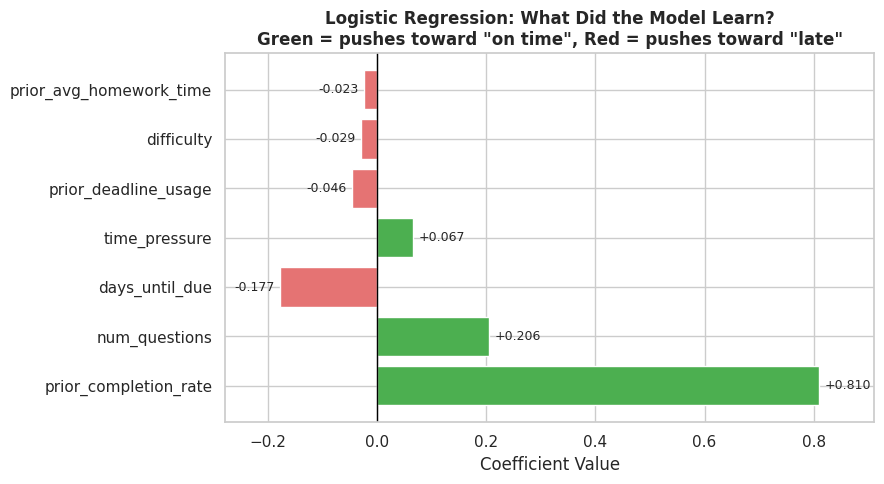

In [8]:
# Visualize the coefficients
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#4CAF50' if v > 0 else '#E57373' for v in coef_df['Coefficient']]
bars = ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
ax.axvline(0, color='black', linewidth=1)
ax.set_xlabel('Coefficient Value')
ax.set_title('Logistic Regression: What Did the Model Learn?\n'
             'Green = pushes toward "on time", Red = pushes toward "late"',
             fontsize=12, fontweight='bold')
ax.set_xlim(coef_df['Coefficient'].min() - 0.1, coef_df['Coefficient'].max() + 0.1)
for bar, val in zip(bars, coef_df['Coefficient']):
    ax.text(val + (0.01 if val >= 0 else -0.01),
            bar.get_y() + bar.get_height()/2,
            f'{val:+.3f}', va='center',
            ha='left' if val >= 0 else 'right', fontsize=9)
plt.tight_layout()
plt.show()

### Reading the Coefficients

The coefficient chart reveals what the model actually learned from the data. Notice:

- **`prior_completion_rate`** has by far the largest positive coefficient — a student's past completion rate is the single most influential factor in the model's prediction. This confirms the finding from Module 2: past behavior is the strongest predictor.
- **`days_until_due`** has a negative coefficient — more lead time is associated with *more* lateness, not less. This seems counterintuitive. Can you think of why this might be?

## TO-DO:

> 🤔 **Think about it:** The model learned that students with more days until the deadline are slightly *more* likely to be late. This is a real pattern in the data — long deadlines are correlated with lower completion rates. Why might that be? What does it tell us about procrastination and human behavior?


*According to my experience, long deadlines correlate with lower completion rates because a student sees a long deadline and overestimates the amount of time that they can push the assignment off until.  My knowledge of this comes mostly from noticing my own behavior, how I respond to deadlines, and how I perform with completing assignments on time.  This inverse correspondence between length of deadlines and completion rate is ultimately because of procrastination, which in this case is shown to hurt the student more when the student in the very occasions where the student has the best conditions.*

### Model 2: Decision Tree

A decision tree learns a sequence of if-then rules. It splits the data repeatedly based on feature thresholds, choosing the split that best separates on-time from late submissions. The result looks like a flowchart.

Decision trees are also highly interpretable — you can literally follow the tree to see why any individual prediction was made.

In [9]:
# ── TRAIN DECISION TREE ──
# max_depth=4 keeps the tree readable; deeper trees tend to overfit
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_model.fit(X_train, y_train)   # decision trees don't need scaling

print('Decision Tree trained.')
print()

# Feature importances
importance_df = pd.DataFrame({
    'Feature': SELECTED_FEATURES,
    'Importance': dt_model.feature_importances_
}).sort_values('Importance', ascending=False)

print('Decision Tree feature importances:')
print(importance_df.to_string(index=False))

Decision Tree trained.

Decision Tree feature importances:
                Feature  Importance
  prior_completion_rate    0.560410
          time_pressure    0.144429
   prior_deadline_usage    0.128712
prior_avg_homework_time    0.108208
          num_questions    0.058241
         days_until_due    0.000000
             difficulty    0.000000


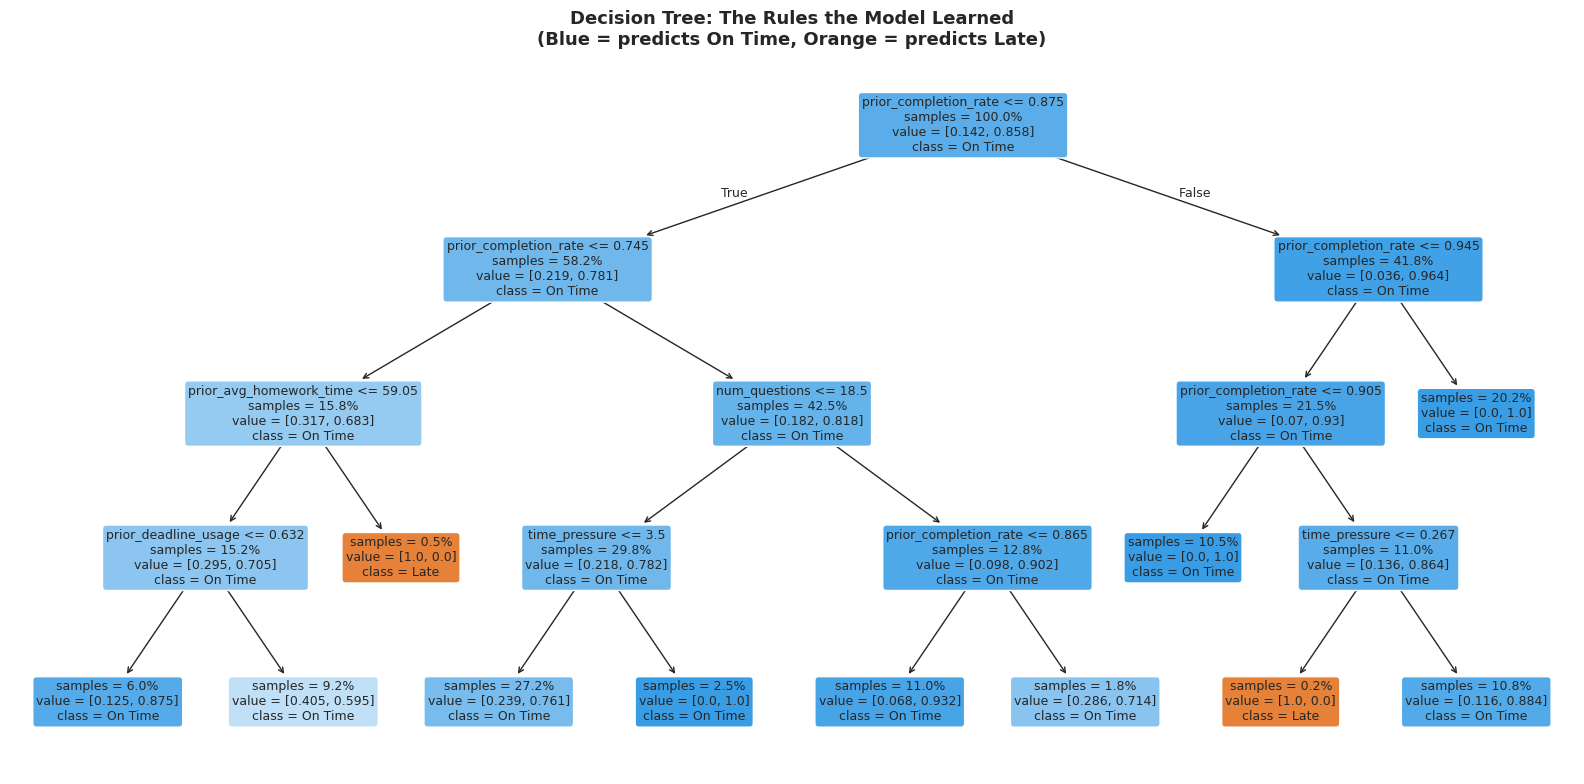

Follow the tree from top to bottom to see the if-then rules.
At each node: go LEFT if the condition is TRUE, RIGHT if FALSE.


In [10]:
# Visualize the decision tree
fig, ax = plt.subplots(figsize=(16, 8))
plot_tree(
    dt_model,
    feature_names=SELECTED_FEATURES,
    class_names=['Late', 'On Time'],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
    impurity=False,
    proportion=True
)
ax.set_title('Decision Tree: The Rules the Model Learned\n'
             '(Blue = predicts On Time, Orange = predicts Late)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print('Follow the tree from top to bottom to see the if-then rules.')
print('At each node: go LEFT if the condition is TRUE, RIGHT if FALSE.')

### How to read a decision tree chart?

Start at the top box and work down. Each box shows:

- **The question** (top line), for example `prior_completion_rate <= 0.875`. Go **left** if the answer is True, **right** if False. The bottom boxes have no question; they are the final answers.
- **samples**: the percentage of training students who reach this box.
- **value**: the share of those students who were `[Late, On Time]`. At the top box, `[0.142, 0.858]` means 14% were late and 86% were on time.
- **class**: the model's prediction for every student who lands here, which is whichever share is larger.
- **Color**: blue predicts On Time, orange predicts Late. The darker the color, the more certain the box is.

**Try it:** a student whose prior completion rate is above 0.945 goes right, then right again. That bottom box predicts On Time, and every student there (`[0.0, 1.0]`) actually was on time.

**Notice:** only two small boxes are orange (0.5% and 0.2% of students). This tree almost never predicts Late.

---

## Part 3: Evaluating the Models — Why Accuracy Is Not Enough

Here is where the lesson becomes genuinely important.

The most natural way to evaluate a classification model is **accuracy** — what percentage of predictions were correct? But accuracy is a deceptive metric, especially when the classes are imbalanced.

In our dataset, 85.8% of submissions are on time. This means a model that **always predicts "on time"** — without looking at any features at all — would be 85.8% accurate. It would score better than many real models. And it would be completely useless.

To understand a model properly, we need to look at **what kinds of mistakes it makes**.

<center><p float="center">
    <img src="https://github.com/danielgoddu-lang/HSC-CIAI-Course-Part-1/blob/main/Part%201/Final%20Project/images/classification.png?raw=1" width="600"/>
</p></center>

In [11]:
# Generate predictions
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]  # probability of on-time

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1] # type: ignore

# Baseline: always predict on time
baseline_pred = np.ones(len(y_test), dtype=int)

print('=== Model Accuracy Comparison ===')
print(f'Always predict "on time" (baseline): {accuracy_score(y_test, baseline_pred)*100:.1f}%')
print(f'Logistic Regression:                 {accuracy_score(y_test, lr_pred)*100:.1f}%')
print(f'Decision Tree:                       {accuracy_score(y_test, dt_pred)*100:.1f}%')
print()


=== Model Accuracy Comparison ===
Always predict "on time" (baseline): 86.0%
Logistic Regression:                 86.0%
Decision Tree:                       85.0%



### Observation(s):

- **Accuracy is the percentage of test students each model got right.** All three were tested on the same 100 students, none of whom they saw during training.

- **Guessing "On Time" for everyone scores 86%.** That tells us 86 of the 100 test students were on time and 14 were late. The baseline gets all 86 on-time students right and all 14 late students wrong.

- **Neither model beats guessing.** Logistic regression ties the baseline at 86%, and the decision tree scores one point lower at 85%. Training a model on the data didn't improve the score at all.

- **Accuracy hides *which* students were wrong.** An accuracy of 86% only means 14 students were predicted wrongly. Those could be all 14 late students, or a model that caught some late students but wrongly flagged the same number of on-time students. Both would score 86%, but only the second would help a teacher.

- **The question we need answered:** did either model catch *any* of the late students? Accuracy can't tell us. A `confusion matrix`, next, can.

 The three numbers are within one point of each other, so they look like three equally good models. In fact, none of them does the job a teacher would want, which is finding the students who are going to be late. Accuracy hides this because 86% of students are on time, so a model can score high just by saying "On Time" to everyone.


### Confusion Matrix

A **confusion matrix** is a small table that shows how a model's predictions compare with what actually happened. It breaks "how accurate is it?" into the specific kinds of right and wrong answers, which is exactly what accuracy alone hides.

For your homework model, it's a 2 × 2 grid:

| | **Predicted Late** | **Predicted On Time** |
|---|---|---|
| **Actually Late** | Caught it ✓ | **Missed it** ✗ |
| **Actually On Time** | **False alarm** ✗ | Correct ✓ |

The four boxes mean:

- **Caught it** (true positive for Late): the student was late, and the model said so.
- **Missed it** (false negative): the student was late, but the model said On Time. This is the mistake your tree makes most.
- **False alarm** (false positive): the student was on time, but the model said Late.
- **Correct** (true negative): the student was on time, and the model said so.

The name comes from the idea that it shows where the model gets "confused," meaning which outcomes it mixes up.

**Question:** For a teacher trying to help struggling students, which mistake is worse, a missed late student or a false alarm? Most will say the miss is worse, since a false alarm just means a friendly check-in. That's the key insight: **different mistakes have different costs, and deciding which ones matter more is a human judgment.**

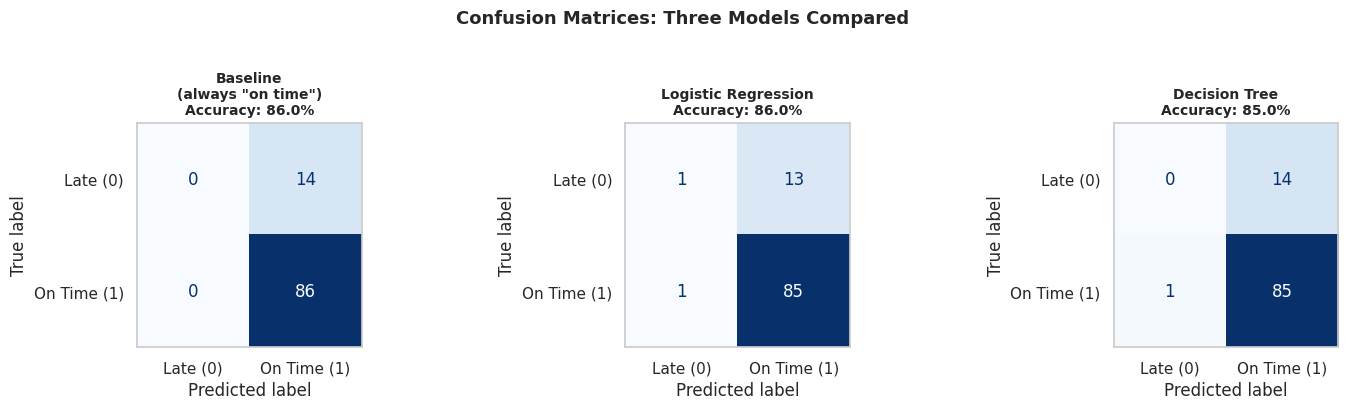

Rows = Actual class | Columns = Predicted class


In [12]:
# ── CONFUSION MATRICES ──
# The confusion matrix shows all four types of outcomes:
#
#  True Negative (TN):  Predicted LATE,    Actually LATE     ✓ correct
#  False Positive (FP): Predicted ON TIME, Actually LATE     ✗ missed a late student
#  False Negative (FN): Predicted LATE,    Actually ON TIME  ✗ wrongly flagged on-time student
#  True Positive (TP):  Predicted ON TIME, Actually ON TIME  ✓ correct

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models = [
    ('Baseline\n(always "on time")', baseline_pred),
    ('Logistic Regression', lr_pred),
    ('Decision Tree', dt_pred),
]

for ax, (title, preds) in zip(axes, models):
    cm = confusion_matrix(y_test, preds)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Late (0)', 'On Time (1)']
    )
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    acc = accuracy_score(y_test, preds)
    ax.set_title(f'{title}\nAccuracy: {acc*100:.1f}%', fontsize=10, fontweight='bold')
    ax.grid(False)

plt.suptitle('Confusion Matrices: Three Models Compared', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()
print('Rows = Actual class | Columns = Predicted class')

- **The test set has 100 students, and only 14 were late.** That imbalance drives everything else in this lesson.

- **The baseline "model" learns nothing and still scores 86%.** By always guessing On Time, it gets every on-time student right and every late student wrong. This is the bar any real model has to beat.
- **Logistic regression ties the baseline at 86%, but by a different route.** It caught 1 of the 14 late students and raised 1 false alarm. One catch traded for one mistake leaves accuracy unchanged.
- **The decision tree is actually worse than guessing.** It caught 0 late students and still made 1 false alarm, so it scores 85%, one point below the baseline.
- **Neither model does the job a teacher would want.** Logistic regression finds 1 of 14 struggling students (about 7%); the tree finds none. Both models have essentially learned to say "On Time."
- **Accuracy hid all of this.** Three numbers within one point of each other (86%, 86%, 85%) describe three models that look nearly identical on paper. Only the confusion matrix shows that two of them are no better than doing nothing.
- **The test set is small, so one student moves the score a full point.** The differences between these models amount to one or two students, which is too few to call one model truly better.
- **The fix is to tell the models that missing a late student matters.** Adding `class_weight='balanced'` to both models makes them take the rare Late cases seriously. You'll try this in Part 6b. They'll catch more late students at the cost of more false alarms, which is usually the right trade for a teacher who would follow a flag with a friendly check-in.
- **The takeaway:** a model that's "86% accurate" can still be useless for its purpose. Always ask what kinds of mistakes it makes, and who pays for them.

### The Critical Finding

Look carefully at the confusion matrix. The logistic regression model is 86% accurate — but it identifies only **1 out of 14 actually-late submissions** correctly. It misses 13 of them, predicting "on time" for students who were actually late. Its accuracy is exactly the same as the baseline that never looks at any features at all.

This is the problem of **class imbalance**. Because 86% of submissions are on time, the model has learned that saying "on time" is almost always safe. It essentially defaults to the majority class and rarely flags anyone as at risk.

From a deployment perspective, this model would almost completely fail at its stated purpose — identifying students who are at risk of late submission. A teacher using this system would receive almost no useful alerts.

#### Two Types of Error — Two Different Harms

| Error Type | What Happened | Harm to Student |
|---|---|---|
| **False Positive** | Predicted "on time" but student was actually late | Student doesn't receive early support they needed |
| **False Negative** | Predicted "late" but student submitted on time | Student is wrongly flagged as at risk; may receive unwanted intervention or face unwarranted scrutiny |

Neither error is harmless. The question of which error is *worse* is a moral judgment, not a technical one.

## TO-DO:

> **Reflection:** Which type of error concerns you more for this specific application — missing students who are actually late, or wrongly flagging students who are on time? What would the real-world consequences of each error be in a school setting?

*Both errors concern me, but missing students who are actually late concerns me more.  Raising false alarms would cause unnecessary check-ins that would be a waste of both student and teacher time.  However, missing a student who actually turns the assignment in late goes against the reason for getting a discriminative AI model to predict completion in the first place.*

---

## Part 4: Better Evaluation — Precision, Recall, and ROC AUC

Since accuracy misleads us here, we need better metrics.

### Defining Better Metrics

For the class we care most about (Late = 0):

RECALL (Sensitivity):
- Of all students who were actually late, what fraction did we catch?
    recall = TP_late / (TP_late + FN_late)
    We want this HIGH — missing late students is the primary failure.

PRECISION:
- Of all students we flagged as late, what fraction were actually late?
    precision = TP_late / (TP_late + FP_late)
    We want this HIGH — wrongly flagging on-time students wastes resources
   and harms those students.

ROC AUC:
- Area under the ROC curve. Measures the model's ability to rank predictions correctly. 1.0 = perfect, 0.5 = no better than random.

Imagine sorting student assignments. Suppose you randomly select:
- One assignment that was submitted late.

- One assignment that was submitted on time.

Your model gives each assignment a lateness score. The higher the score, the more likely the model thinks the assignment was late. AUC measures how often the model gives the late assignment a higher score than the on-time assignment.

In [13]:
lr_auc = roc_auc_score(y_test, lr_prob)
dt_auc = roc_auc_score(y_test, dt_prob)

print('=== Better Metrics ===')
print()
print(f'Logistic Regression ROC AUC: {lr_auc:.3f} - Roughly {lr_auc:.3f} of randomly chosen late/on-time pairs are ranked correctly.')
print(f'Decision Tree ROC AUC:       {dt_auc:.3f} - Roughly {dt_auc:.3f} of those pairs are ranked correctly.' )
print(f'(Random baseline AUC = 0.500)')
print()

# Recall for the "late" class specifically
cm_lr = confusion_matrix(y_test, lr_pred)
cm_dt = confusion_matrix(y_test, dt_pred)

def late_recall(cm):
    tn, fp, fn, tp = cm.ravel()
    # For the "late" class: tn = correct late, fp = late predicted on-time
    return tn / (tn + fp) if (tn + fp) > 0 else 0

print(f'Recall for "late" class (how many late submissions we caught):')
print(f'  Logistic Regression: {late_recall(cm_lr)*100:.1f}% - caught about this amount of late submissions; missed the rest')
print(f'  Decision Tree:       {late_recall(cm_dt)*100:.1f}% - caught about this amount of late submissions; missed the rest')
print(f'  Baseline (always on-time): 0.0%')

=== Better Metrics ===

Logistic Regression ROC AUC: 0.782 - Roughly 0.782 of randomly chosen late/on-time pairs are ranked correctly.
Decision Tree ROC AUC:       0.708 - Roughly 0.708 of those pairs are ranked correctly.
(Random baseline AUC = 0.500)

Recall for "late" class (how many late submissions we caught):
  Logistic Regression: 7.1% - caught about this amount of late submissions; missed the rest
  Decision Tree:       0.0% - caught about this amount of late submissions; missed the rest
  Baseline (always on-time): 0.0%


### Observation(s):

- **AUC says both models are better than guessing.** A random guesser scores 0.500. Logistic regression scores 0.782 and the decision tree 0.708, so both have learned something real about which students are more likely to be late.

- **Recall says they almost never act on it.** Recall for the late class is the share of late students the model actually caught. Logistic regression caught 7.1%, which is 1 of the 14 late students. The decision tree caught none, no better than always guessing "On Time."

- **How can both be true?** AUC checks whether the model puts students in the right *order*, with late students getting lower on-time scores. Recall checks who actually gets *flagged* at the default cutoff of 0.5. The models rank students reasonably well, but almost nobody's score falls below 0.5, so almost nobody is flagged.

- **Every metric answers a different question.** Accuracy asks "how many did it get right?" AUC asks "does it rank students in the right order?" Recall asks "how many late students did it catch?" A model can look good on one and fail on another, which is why we never judge a model by a single number.

### Let's plot the ROC curve

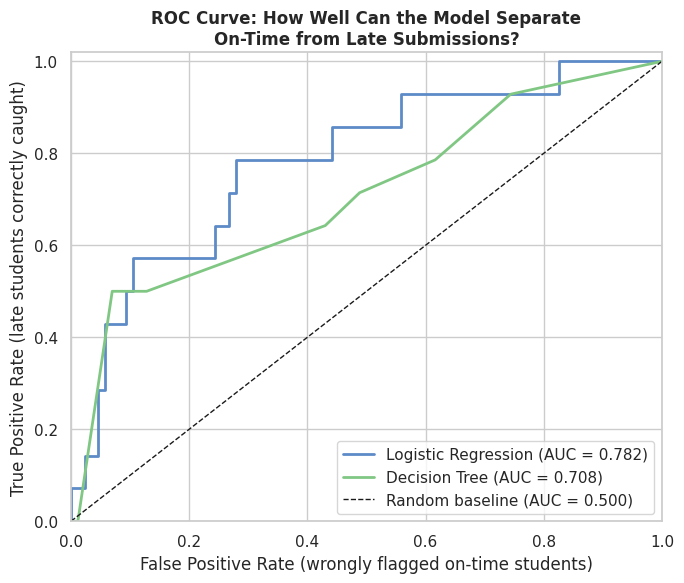

In [14]:
# ── ROC CURVE ──
# The ROC curve shows the trade-off between true positive rate and false
# positive rate at different prediction thresholds.
# A model that hugs the top-left corner is better.
# The diagonal line represents a random guesser.

fig, ax = plt.subplots(figsize=(7, 6))

for label, prob, auc, color in [
    ('Logistic Regression', lr_prob, lr_auc, '#5C8BC7'),
    ('Decision Tree', dt_prob, dt_auc, '#81C784'),
]:
    fpr, tpr, _ = roc_curve(1 - y_test, 1 - prob)   # Late is the class we want to catch
    ax.plot(fpr, tpr, label=f'{label} (AUC = {auc:.3f})', linewidth=2, color=color)

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random baseline (AUC = 0.500)')
ax.set_xlabel('False Positive Rate (wrongly flagged on-time students)')
ax.set_ylabel('True Positive Rate (late students correctly caught)')
ax.set_title('ROC Curve: How Well Can the Model Separate\nOn-Time from Late Submissions?',
             fontsize=12, fontweight='bold')
ax.legend()
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.show()

### Observation(s):

- **AUC is the area under each curve.** The chart is a square with an area of 1, so the area under a curve is a number between 0 and 1.

- - **What AUC means:** pick one student who was late and one who was on time. AUC is the chance the model gave the late student the lower on-time score, meaning it correctly judged that student as more likely to be late.

- **0.5 means guessing.** The dashed diagonal cuts the square exactly in half, so a model that guesses at random scores 0.5. Above 0.5 is better than guessing; below 0.5 means the model has things backwards.

- - **Both models beat guessing.** Logistic regression scores 0.78: for 78% of late/on-time pairs, it gave the late student the lower on-time score. The decision tree scores 0.71, or 71% of pairs. Logistic regression's curve sits higher, so it covers more area.

- **A good AUC doesn't make a good tool.** Logistic regression ranks students fairly well, yet at the default setting it caught only 1 of the 14 late students. AUC measures whether the model puts students in the right *order*, not whether it flags the right ones. Where we draw the line is a separate decision, made by people.

---

## Part 5: Understanding the Predictions — Who Gets It Wrong?

Aggregate metrics tell us how the model performs on average. But AI ethics requires us to look at individual cases — especially the ones the model gets wrong. Who are the students the model misses or mislabels?

In [15]:
# Build a results dataframe combining predictions with the original rows.
# This keeps analysis columns available even when they were not model features.
RESULT_DISPLAY_COLS = [
    'student_id',
    'assignment_type',
    'difficulty',
    'days_until_due',
    'prior_completion_rate',
    'prior_avg_grade',
]

missing_display_cols = [col for col in RESULT_DISPLAY_COLS if col not in df.columns]
if missing_display_cols:
    raise KeyError(f'Missing expected dataset columns: {missing_display_cols}')

results = df.loc[X_test.index, RESULT_DISPLAY_COLS].copy()
results['actual']           = y_test.values
results['predicted']        = lr_pred
results['prob_on_time']     = lr_prob.round(3)
results['outcome'] = results.apply(
    lambda r: 'Correct' if r['actual'] == r['predicted'] else
              ('Missed late' if r['actual'] == 0 else 'Wrongly flagged'), axis=1
)

print('Summary of prediction outcomes:')
print(results['outcome'].value_counts())
print()

Summary of prediction outcomes:
outcome
Correct            86
Missed late        13
Wrongly flagged     1
Name: count, dtype: int64



### Observation(s):

- **The logistic regression model was wrong 14 times, and 13 of those were late students it missed.** It said they would be on time, and they weren't.

- **Its mistakes are lopsided.** It wrongly flagged only 1 on-time student, because it almost never flags anyone. Nearly every mistake landed on a student who needed help.

- **Each number is a person.** The next two cells show exactly who the model missed and who it wrongly flagged.

In [16]:
# Students the model MISSED — actually late, predicted on time
# If this cell is run after an older results cell, add the display columns now.
if 'RESULT_DISPLAY_COLS' not in globals():
    RESULT_DISPLAY_COLS = [
        'student_id',
        'assignment_type',
        'difficulty',
        'days_until_due',
        'prior_completion_rate',
        'prior_avg_grade',
    ]

missing_display_cols = [col for col in RESULT_DISPLAY_COLS if col not in df.columns]
if missing_display_cols:
    raise KeyError(f'Missing expected dataset columns: {missing_display_cols}')

missing_result_cols = [col for col in RESULT_DISPLAY_COLS if col not in results.columns]
if missing_result_cols:
    results = results.join(df.loc[results.index, missing_result_cols])

missed = results[results['outcome'] == 'Missed late'].sort_values('prob_on_time', ascending=False)
print('Students the model MISSED (actually late, predicted on time):')
print('These students needed support, the AI gave them none.')
print()
print(missed[RESULT_DISPLAY_COLS + ['prob_on_time']].to_string(index=False))

Students the model MISSED (actually late, predicted on time):
These students needed support, the AI gave them none.

student_id assignment_type  difficulty  days_until_due  prior_completion_rate  prior_avg_grade  prob_on_time
      S145           essay           1               1                   0.91             93.9         0.943
      S115       quiz_prep           5               6                   0.89             93.7         0.912
      S111          coding           5               6                   0.86             96.6         0.890
      S134         reading           2               1                   0.77             88.4         0.832
      S121          coding           5               5                   0.82             75.7         0.827
      S147       quiz_prep           4               6                   0.79             91.0         0.803
      S134           essay           4               4                   0.72            100.0         0.754
      S121 

### Observation(s):

- **Every missed student got an on-time score above 0.5.** That's why the model said "On Time" for all of them. Some were close (S150 at 0.554); others weren't close at all.

- **The model was most confident about students with the best records.** The top three had completion rates of 0.86–0.91, and the model gave them a 89–94% chance of being on time. They were late anyway. A strong past record made the model trust them, and it was wrong.

- **Some students were missed more than once.** S134, S121 and S147 each appear twice, so 3 students account for 6 of the 13 misses.

- **No obvious pattern explains the misses.** They include easy and hard assignments, short and long deadlines, and every assignment type. Whatever made these students late isn't in the data at all.

- **The model only knows the past.** It can't know that a reliable student got sick, had a family emergency, or simply had a hard week. It judged each student by their record, and their record didn't tell the story.

- **Note:** `prior_avg_grade` is shown here for context only. The model doesn't use it.

In [17]:
# Students the model WRONGLY FLAGGED — on time, predicted late
# If this cell is run after an older results cell, add the display columns now.
if 'RESULT_DISPLAY_COLS' not in globals():
    RESULT_DISPLAY_COLS = [
        'student_id',
        'assignment_type',
        'difficulty',
        'days_until_due',
        'prior_completion_rate',
        'prior_avg_grade',
    ]

missing_display_cols = [col for col in RESULT_DISPLAY_COLS if col not in df.columns]
if missing_display_cols:
    raise KeyError(f'Missing expected dataset columns: {missing_display_cols}')

missing_result_cols = [col for col in RESULT_DISPLAY_COLS if col not in results.columns]
if missing_result_cols:
    results = results.join(df.loc[results.index, missing_result_cols])

flagged = results[results['outcome'] == 'Wrongly flagged'].sort_values('prob_on_time')
print('Students WRONGLY FLAGGED (on time, predicted late):')
print('These students did fine, the AI suggested they were at risk.')
print()
print(flagged[RESULT_DISPLAY_COLS + ['prob_on_time']].to_string(index=False))

Students WRONGLY FLAGGED (on time, predicted late):
These students did fine, the AI suggested they were at risk.

student_id assignment_type  difficulty  days_until_due  prior_completion_rate  prior_avg_grade  prob_on_time
      S127           essay           4               6                   0.65            100.0         0.471


### Observation(s):

- **Only one student was wrongly flagged.** That's not because the model is careful; it's because it almost never flags anyone.

- **The flag came down to a few hundredths.** S127's score was 0.471, just under the 0.5 cutoff. S150, on the missed list, scored 0.554 and was actually late. Two students with nearly the same score ended up on opposite sides of the line, and the model got both wrong.

- **The flag was based on S127's past, not on this assignment.** S127's completion rate of 0.65 is on the low side, and this assignment had a long deadline (6 days), which the model links to lateness. S127 turned it in on time anyway.

- **S127 also has a perfect average grade of 100.** The model doesn't use grades, so it couldn't see that this student does excellent work. It only saw a record of missed deadlines.

- **This is the other side of the missed list.** There, strong records hid students who needed help. Here, a weaker record labeled a student who was doing fine. Either way, the model judged the student by their past.

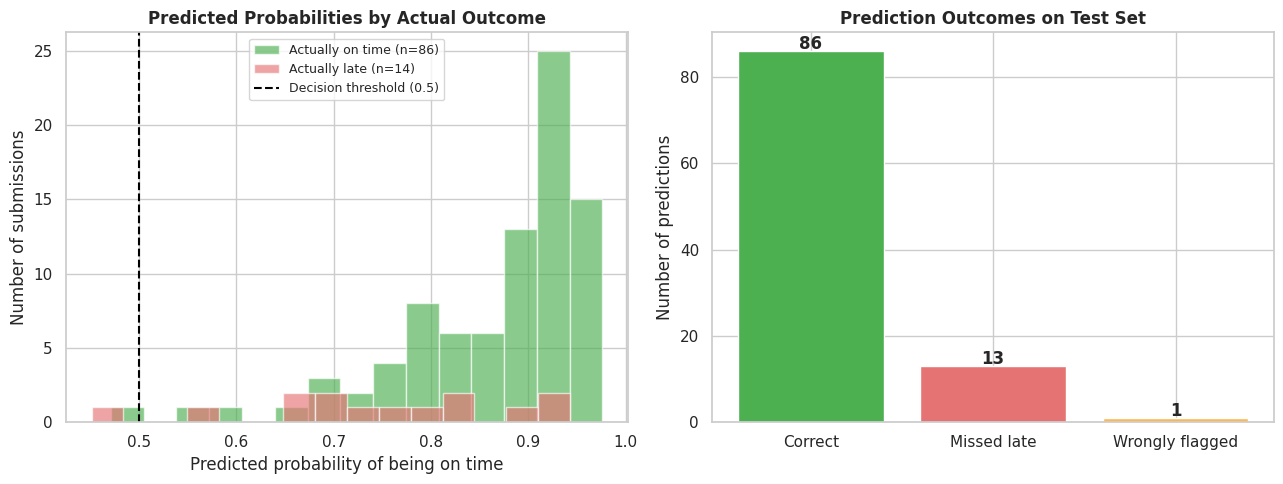

In [18]:
# Distribution of prediction probabilities
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: distribution of predicted probabilities
for label, color, name in [(1, '#4CAF50', 'Actually on time'), (0, '#E57373', 'Actually late')]:
    subset = results[results['actual'] == label]['prob_on_time']
    axes[0].hist(subset, bins=15, alpha=0.65, color=color,
                 label=f'{name} (n={len(subset)})')
axes[0].axvline(0.5, color='black', linestyle='--', linewidth=1.5, label='Decision threshold (0.5)')
axes[0].set_xlabel('Predicted probability of being on time')
axes[0].set_ylabel('Number of submissions')
axes[0].set_title('Predicted Probabilities by Actual Outcome', fontweight='bold')
axes[0].legend(fontsize=9)

# Right: outcome breakdown
outcome_counts = results['outcome'].value_counts()
colors_map = {'Correct': '#4CAF50', 'Missed late': '#E57373', 'Wrongly flagged': '#FFB74D'}
bar_colors = [colors_map[o] for o in outcome_counts.index]
axes[1].bar(outcome_counts.index, outcome_counts.values, color=bar_colors)
axes[1].set_title('Prediction Outcomes on Test Set', fontweight='bold')
axes[1].set_ylabel('Number of predictions')
for i, v in enumerate(outcome_counts.values):
    axes[1].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Part 6: Adjusting the Threshold

The default decision threshold is 0.5: predict "late" if the model assigns less than 50% probability of on-time submission. But this threshold is arbitrary. Let's explore what happens when we change it.

In [19]:
# Explore different decision thresholds
thresholds = [0.50, 0.70, 0.80, 0.85, 0.90, 0.95]

print('{:<12} {:<12} {:<14} {:<18} {}'.format('Threshold', 'Accuracy', 'Late recall', 'False flag rate', '% flagged as late'))
print('-' * 72)

for thresh in thresholds:
    preds = (lr_prob >= thresh).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    acc = accuracy_score(y_test, preds)
    late_rec = tn / (tn + fp) if (tn + fp) > 0 else 0
    false_flag_rate = fn / (fn + tp) if (fn + tp) > 0 else 0
    flagged_pct = (preds == 0).mean()
    print(f'{thresh:<12.2f} {acc:<12.3f} {late_rec:<14.3f} {false_flag_rate:<18.3f} {flagged_pct:.1%}')

print()
print('Trade-off: Higher threshold catches more late students but flags more on-time students.')

Threshold    Accuracy     Late recall    False flag rate    % flagged as late
------------------------------------------------------------------------
0.50         0.860        0.071          0.012              2.0%
0.70         0.870        0.429          0.058              11.0%
0.80         0.740        0.571          0.233              28.0%
0.85         0.690        0.786          0.326              39.0%
0.90         0.530        0.857          0.523              57.0%
0.95         0.240        1.000          0.884              90.0%

Trade-off: Higher threshold catches more late students but flags more on-time students.


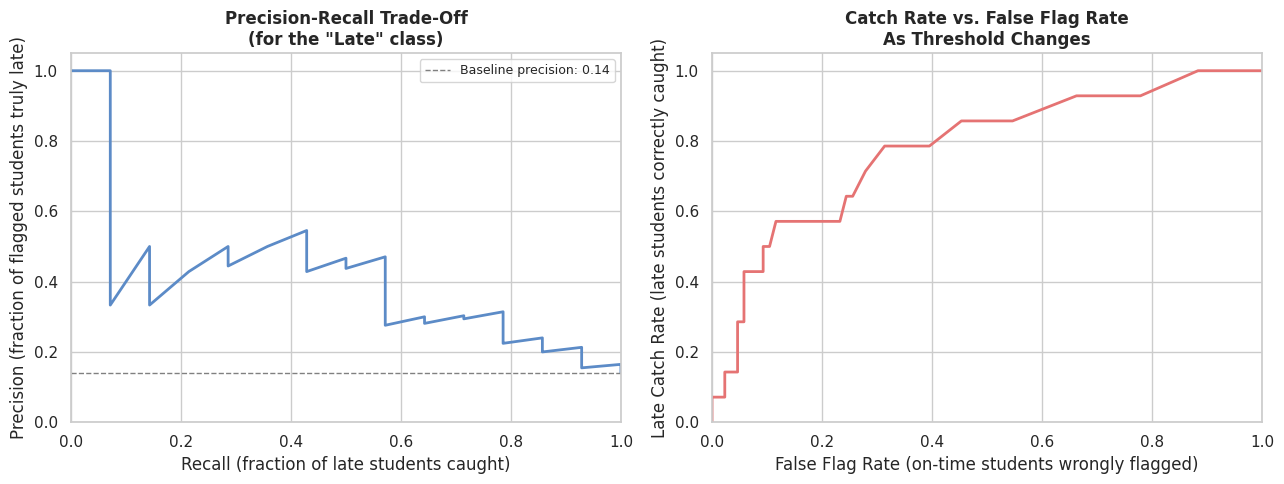

In [20]:
# Visualize the precision-recall trade-off
from sklearn.metrics import precision_recall_curve

# We want precision/recall for the LATE class (class 0)
# sklearn's precision_recall_curve works on the positive class,
# so we use 1 - prob_on_time as the score for "lateness"
lr_prob_late = 1 - lr_prob
precision, recall, thresholds_pr = precision_recall_curve(1 - y_test, lr_prob_late)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Precision-recall curve for late class
axes[0].plot(recall, precision, color='#5C8BC7', linewidth=2)
axes[0].set_xlabel('Recall (fraction of late students caught)')
axes[0].set_ylabel('Precision (fraction of flagged students truly late)')
axes[0].set_title('Precision-Recall Trade-Off\n(for the "Late" class)', fontweight='bold')
axes[0].set_xlim([0, 1])
axes[0].set_ylim([0, 1.05])
late_share = (y_test == 0).mean()  # precision of guessing at random
axes[0].axhline(late_share, color='gray', linestyle='--', linewidth=1,
                label=f'Baseline precision: {late_share:.2f}')
axes[0].legend(fontsize=9)

# Show catch rate vs false flag rate at different thresholds
catch_rates, false_flag_rates = [], []
for thresh in np.arange(0.4, 1.0, 0.01):
    preds = (lr_prob >= thresh).astype(int)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    catch_rates.append(tn / (tn + fp) if (tn + fp) > 0 else 0)
    false_flag_rates.append(fn / (fn + tp) if (fn + tp) > 0 else 0)

axes[1].plot(false_flag_rates, catch_rates, color='#E57373', linewidth=2)
axes[1].set_xlabel('False Flag Rate (on-time students wrongly flagged)')
axes[1].set_ylabel('Late Catch Rate (late students correctly caught)')
axes[1].set_title('Catch Rate vs. False Flag Rate\nAs Threshold Changes', fontweight='bold')
axes[1].set_xlim([0, 1])
axes[1].set_ylim([0, 1.05])

plt.tight_layout()
plt.show()

### Observation(s):

- **Precision asks: when the model flags a student, how often is it right?** Recall asks: of all the late students, how many did it catch? This chart shows what happens to one as the other goes up.

- **Catching more late students means more of the flags are wrong.**
  - To catch 8 of the 14 late students, the model flags 17 students; about half of those flags (8 of 17) are correct.
  - To catch 11 of the 14, it flags 35 students; fewer than a third (11 of 35) are correct.
  - To catch all 14, it flags 85 students; only 1 flag in 6 is correct.

- **The gray line is guessing.** Only 14% of students were late, so flagging students at random would be right 14% of the time. The model always stays above that line, but by the time it catches every late student, it is barely better than random.

- **Why the line zigzags:** each time the model flags another late student, precision jumps up; each time it flags an on-time student, precision slides down. With only 14 late students, every one makes a visible jump.

- **Every wrong flag is a real student.** At the setting that catches 11 late students, 24 students who turned their work in on time would be treated as a problem. Is catching 3 more late students worth flagging 47 more on-time ones?

### Why the Model Is Overconfident

Look at the left chart. Notice that the model rarely assigns low probabilities to anyone — most predictions cluster in the 0.7 - 1.0 range. The model has learned that almost everyone submits on time, so it almost always predicts high probabilities of on-time submission.

This **overconfidence** means the default decision threshold of 0.5 catches very few late students. You could lower the threshold — flag any student with a probability below 0.9 as "at risk" — but this would dramatically increase false positives (wrongly flagging students).

This is the fundamental **precision-recall trade-off**: you can catch more late students, but only by flagging more on-time students incorrectly. There is no free lunch.

## TO-DO:

> **Reflection:** If you were a teacher deploying this system, what threshold would you set, and why? What would it mean to flag 40% of students as "at risk" in order to catch 80% of the genuinely late ones?

*If I was a teacher deploying this system, I would set the threshold to only flag students that have 50% chance of being late or more.  This is assuming that I could get an AI that predict with an accuracy that is actually useful.  So that any percent chance value of a student being late or not is truly what cannot be known from the data.  
To flag 40% of student's "at risk" in order to catch 80% of the genuinely late ones would be practical as long as the AI flagged students who were actually at reasonable risk in a way that I did not already know.  No teacher needs an AI to tell him that 100% of his students are at risk - he already knows that by nature of them beings students.  
That is to say, that this AI seems useless at this point.*

---

## Part 6b: Telling the Model What Matters — Class Weights

Adjusting the threshold changes how we *read* the model's output. But we can also change what the model *learns*.

By default, every training example counts equally. Since about 86% of submissions are on time, the model learns that guessing "on time" is almost always safe. Setting `class_weight='balanced'` tells the model to weight each class by how rare it is. In our training data, each late submission now counts about **six times** as much as an on-time one.

| Lever | When it acts | What it does |
|---|---|---|
| **Threshold** (Part 6) | After training | Changes how we *read* the model's probabilities |
| **Class weight** (Part 6b) | During training | Changes what the model *learns* |

Both are ways of writing a human value judgment into code: *we care more about missing a struggling student than about a false alarm.*

> 🔍 **Look for this:** For logistic regression, balancing mostly shifts the model's baseline, so its results often resemble one of the rows in the Part 6 threshold table. For the decision tree, balancing changes the splits themselves — it may learn genuinely different rules.

Training set: 57 late, 343 on time
With balanced weights, each late example counts 6.0x as much as an on-time one

Model                             Accuracy  Late caught  False alarms
--------------------------------------------------------------------
Logistic Regression                  86.0%       1 / 14        1 / 86
Logistic Regression (balanced)       69.0%      11 / 14       28 / 86
Decision Tree                        85.0%       0 / 14        1 / 86
Decision Tree (balanced)             39.0%       9 / 14       56 / 86


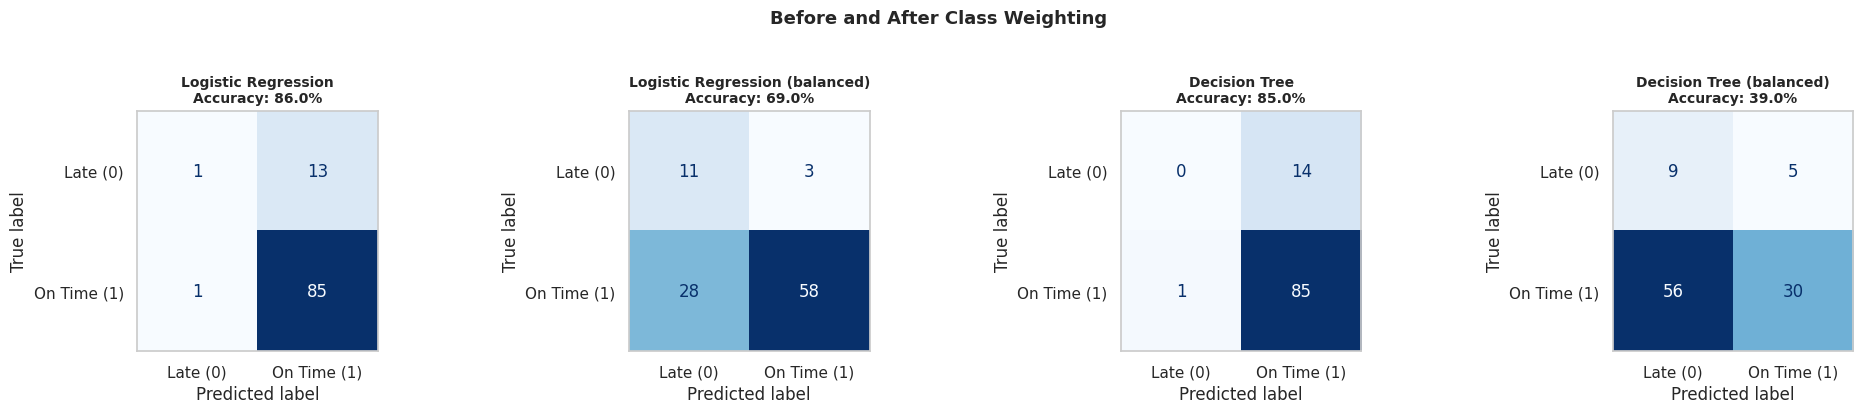

In [21]:
# ── TRAIN BALANCED VERSIONS ──
# Same settings as before; the ONLY change is class_weight='balanced'

n_late = (y_train == 0).sum()
n_on_time = (y_train == 1).sum()
print(f'Training set: {n_late} late, {n_on_time} on time')
print(f'With balanced weights, each late example counts {n_on_time / n_late:.1f}x as much as an on-time one')
print()

lr_bal = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr_bal.fit(X_train_scaled, y_train)

dt_bal = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt_bal.fit(X_train, y_train)

lr_bal_pred = lr_bal.predict(X_test_scaled)
dt_bal_pred = dt_bal.predict(X_test)

comparison = [
    ('Logistic Regression',            lr_pred),
    ('Logistic Regression (balanced)', lr_bal_pred),
    ('Decision Tree',                  dt_pred),
    ('Decision Tree (balanced)',       dt_bal_pred),
]

print(f"{'Model':<32} {'Accuracy':>9} {'Late caught':>12} {'False alarms':>13}")
print('-' * 68)
for name, preds in comparison:
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    print(f"{name:<32} {accuracy_score(y_test, preds):>9.1%} "
          f"{f'{tn} / {tn+fp}':>12} {f'{fn} / {fn+tp}':>13}")

# Side-by-side confusion matrices
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, preds) in zip(axes, comparison):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, preds),
        display_labels=['Late (0)', 'On Time (1)']
    ).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'{name}\nAccuracy: {accuracy_score(y_test, preds):.1%}',
                 fontsize=10, fontweight='bold')
    ax.grid(False)
plt.suptitle('Before and After Class Weighting', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

---

## Part 7: What the Model Results Mean Ethically

You have now built, trained, and evaluated a real AI model. Let's be honest about what it can and cannot do.

### What the Model Can Do
- Make predictions that are right about 86% of the time, no better than always guessing "on time"
- Identify that `prior_completion_rate` is strongly predictive
- With adjusted thresholds or class weights, flag more late-risk students — but at the cost of flagging many on-time students too

### What the Model Cannot Do
- Explain *why* any individual student submitted late
- Account for circumstances it has no data on: illness, family crises, learning differences
- Change its prediction for a student who has genuinely changed
- Feel compassion, exercise mercy, or recognize a student as a person rather than a pattern

### The Catholic Judgment

*Magnifica Humanitas* (no. 102) warns specifically about systems in high-stakes contexts that "do not know compassion, mercy, forgiveness, and above all, the hope that people are able to change." This is not a poetic statement — it is a precise description of what this model lacks and what any model lacks.

The Compendium of the Social Doctrine of the Church insists that the human person is always the **principle, subject, and purpose** of institutions — never their object. A homework prediction system that routes a student toward intervention, scrutiny, or reduced support based on their past record without any human judgment applied to their individual circumstances has violated this principle, regardless of its accuracy rate.

In [22]:
# Final model summary for your project report
# Compute 5-fold CV accuracy since it was not defined yet
lr_cv = cross_val_score(lr_model, X_train_scaled, y_train, cv=5)

print('=' * 65)
print('MODEL EVALUATION REPORT  Module 3')
print('=' * 65)
print()
print(f'Model type:          Logistic Regression')
print(f'Features used:       {SELECTED_FEATURES}')
print(f'Training set size:   {len(X_train)}')
print(f'Test set size:       {len(X_test)}')
print()
print(f'Test accuracy:       {accuracy_score(y_test, lr_pred)*100:.1f}%')
print(f'ROC AUC:             {lr_auc:.3f}')
print(f'5-fold CV accuracy:  {lr_cv.mean():.3f} ± {lr_cv.std():.3f}')
print()
tn, fp, fn, tp = confusion_matrix(y_test, lr_pred).ravel()
print(f'Late students correctly caught: {tn} / {tn+fp} ({tn/(tn+fp)*100:.0f}%)')
print(f'On-time students wrongly flagged: {fn} / {fn+tp} ({fn/(fn+tp)*100:.0f}%)')
print()
print('Most influential feature:        prior_completion_rate')
print('Feature most pushing toward late: days_until_due (negative coef)')
print()
print('ETHICAL FLAGS:')
print('  prior_completion_rate  feedback loop risk')
print('  prior_deadline_usage   judges a student by past habits (same risk)')
print('  prior_avg_grade        may encode socioeconomic advantage')
print('  Model catches only', f'{tn/(tn+fp)*100:.0f}%', 'of late submissions at 0.5 threshold')
print('=' * 65)

MODEL EVALUATION REPORT  Module 3

Model type:          Logistic Regression
Features used:       ['num_questions', 'difficulty', 'days_until_due', 'prior_avg_homework_time', 'time_pressure', 'prior_completion_rate', 'prior_deadline_usage']
Training set size:   400
Test set size:       100

Test accuracy:       86.0%
ROC AUC:             0.782
5-fold CV accuracy:  0.845 ± 0.013

Late students correctly caught: 1 / 14 (7%)
On-time students wrongly flagged: 1 / 86 (1%)

Most influential feature:        prior_completion_rate
Feature most pushing toward late: days_until_due (negative coef)

ETHICAL FLAGS:
  prior_completion_rate  feedback loop risk
  prior_deadline_usage   judges a student by past habits (same risk)
  prior_avg_grade        may encode socioeconomic advantage
  Model catches only 7% of late submissions at 0.5 threshold


---

## Summary and What's Coming Next

### What You Accomplished in This Module

- Prepared data for modeling: encoding, scaling, and a principled train/test split
- Trained two interpretable models — logistic regression and decision tree — and understood what each learned
- Discovered that **86% accuracy is misleading** when the model misses 13 of the 14 late students it should flag
- Learned to evaluate models using confusion matrices, recall, precision, and ROC AUC
- Explored the precision-recall trade-off: catching more late students always comes at the cost of flagging more on-time students
- Used class weights to tell the model that a missed late student matters more than a false alarm, and saw that this is a human value judgment, not a technical default
- Identified the specific students the model got wrong — and considered what that means for real people

### Coming in Module 4 (Classes 7-8)

Module 4 will focus on **bias auditing**: investigating whether the model performs equally well across different student groups and assignment types, or whether it systematically fails for some students more than others. This is where the ethical analysis deepens significantly — a model that is 86% accurate overall may be 95% accurate for some students and 60% accurate for others, and those differences are not random.

---

> **A thought to carry forward:** The balanced model you built in Part 6b catches more of the late students — but look at how many on-time students it flags along the way. If a teacher acted on every flag — following up with students, contacting parents, or adding notes to files — many of those actions would be directed at students who did nothing wrong. Who decides how many false alarms are acceptable to catch one struggling student? What does that mean for how cautiously this system should be deployed — if at all?